In [2]:
import os
import time
import warnings

import torch
import torchvision.transforms.functional as F
import matplotlib.pyplot as plt
import coremltools as ct

from torch.export import export
from torchvision.io import decode_image

from executorch import version
from executorch.runtime import Runtime
from executorch.exir import to_edge_transform_and_lower
from executorch.backends.apple.coreml.partition import CoreMLPartitioner
from executorch.backends.apple.coreml.compiler import CoreMLBackend

from model import ssdlite320_mobilenet_v3_large, SSDLite320_MobileNet_V3_Large_Weights

warnings.simplefilter("ignore", FutureWarning)
print("Executorch version: ", version.__version__)

Executorch version:  1.1.0


In [3]:
model_constructors = [
    ssdlite320_mobilenet_v3_large,
]

model_weights = [
    SSDLite320_MobileNet_V3_Large_Weights.DEFAULT,
]

In [4]:
# Directory to save the exported .pte file
EXPORT_DIR = "exports"

# Path to the exported .pte file
MODEL_PATH: dict[str, str] = {}

# Suffix for models
SUFFIX = "_coreml_fp32"

# Resize size for the input image, based on the name
RESIZE_SIZE = [320, 320]


# Based on the definition of the `transforms` field in the
# `SSDLite320_MobileNet_V3_Large_Weights` class
def preprocess(img: torch.Tensor) -> torch.Tensor:
    img = F.resize(img, RESIZE_SIZE)
    img = F.convert_image_dtype(img, torch.float)
    return img

In [5]:
def visualize_predictions(img_tensor, prediction, score_threshold=0.5, title=""):
    categories = model_weights[0].meta["categories"]
    # C,H,W float [0,1] → H,W,C numpy
    img_np = img_tensor.permute(1, 2, 0).detach().numpy().clip(0, 1)

    boxes = prediction["boxes"].detach()
    labels = prediction["labels"].detach()
    scores = prediction["scores"].detach()

    keep = scores > score_threshold
    boxes, labels, scores = boxes[keep], labels[keep], scores[keep]

    fig, ax = plt.subplots()
    ax.imshow(img_np)
    ax.set_title(title)
    ax.axis("off")

    for box, label, score in zip(boxes, labels, scores):
        x1, y1, x2, y2 = box.tolist()
        ax.add_patch(plt.Rectangle((x1, y1), x2 - x1, y2 - y1, linewidth=2, edgecolor="red", facecolor="none"))
        ax.text(x1, y1 - 4, f"{categories[int(label.item())]}: {score:.2f}")

    plt.tight_layout()
    plt.show()

In [6]:
for constructor, weights in zip(model_constructors, model_weights):
    model = constructor(weights=weights).eval()
    inputs = ([torch.randn(3, *RESIZE_SIZE)],)

    program = to_edge_transform_and_lower(
        export(model, inputs),
        partitioner=[
            CoreMLPartitioner(
                compile_specs=CoreMLBackend.generate_compile_specs(compute_precision=ct.precision.FLOAT32),
                skip_ops_for_coreml_delegation=["aten.select_scatter.default"],
            )
        ],
    )
    program = program.to_executorch()

    with open(path := f"{EXPORT_DIR}/{constructor.__name__}{SUFFIX}.pte", "wb") as f:
        MODEL_PATH[constructor.__name__] = path
        f.write(program.buffer)

    print(f"Exported {MODEL_PATH[constructor.__name__]}\n")

Running MIL backend_mlprogram pipeline: 100%|██████████| 12/12 [00:00<00:00, 116.50 passes/s]


Exported exports/ssdlite320_mobilenet_v3_large_coreml_fp32.pte



In [7]:
print("Verifying models...")

for constructor, weights in zip(model_constructors, model_weights):
    print(constructor.__name__.upper())
    path = MODEL_PATH[constructor.__name__]

    # --- ExecuTorch Inference ---
    img = decode_image("assets/dog.png")
    img = preprocess(img)
    print(img.shape)

    t = time.perf_counter()
    runtime = Runtime.get()
    program = runtime.load_program(path)
    output = program.load_method("forward").execute([img])  # type: ignore
    t = time.perf_counter() - t

    print(
        f"Model size: {os.path.getsize(path) / 1024 / 1024:.2f}MB\n"
        f"Run successfully via ExecuTorch in {t:.2f} seconds."
    )

    # --- PyTorch Eager Reference ---
    img = decode_image("assets/dog.png").unsqueeze(0)
    img = F.resize(img, RESIZE_SIZE, interpolation=F.InterpolationMode.BILINEAR, antialias=True)

    ref_model = constructor(weights=weights).eval()
    ref_output = ref_model(weights.transforms()(img))[0]

    torch.testing.assert_close(output[0], ref_output["boxes"], rtol=1e-3, atol=1e-4)
    torch.testing.assert_close(output[1], ref_output["scores"], rtol=1e-3, atol=1e-4)
    torch.testing.assert_close(output[2], ref_output["labels"], rtol=1e-3, atol=1e-4)
    print("Comparison passed!\n")

[program.cpp:154] InternalConsistency verification requested but not available
[ETCoreMLModelManager.mm:478] Cache Miss: Compiled Model with identifier=executorch_c8db98e3-54dc-4043-9fc8-c7ed7a9ef71a_all was not found in the models cache.
[ETCoreMLModelManager.mm:457] The model in the pte file is not pre-compiled.  Compiling with a 5 min timeout.
[ETCoreMLModelManager.mm:490] Successfully got compiled model with identifier=executorch_c8db98e3-54dc-4043-9fc8-c7ed7a9ef71a_all.  Transferring ownership to assetManager.


Verifying models...
SSDLITE320_MOBILENET_V3_LARGE
torch.Size([3, 320, 320])


[ETCoreMLModelManager.mm:478] Cache Miss: Compiled Model with identifier=executorch_d3df711d-f007-44a7-b11b-3a922679698b_all was not found in the models cache.
[ETCoreMLModelManager.mm:457] The model in the pte file is not pre-compiled.  Compiling with a 5 min timeout.
[ETCoreMLModelManager.mm:490] Successfully got compiled model with identifier=executorch_d3df711d-f007-44a7-b11b-3a922679698b_all.  Transferring ownership to assetManager.


Model size: 14.83MB
Run successfully via ExecuTorch in 5.26 seconds.
Comparison passed!



Visual inspection...


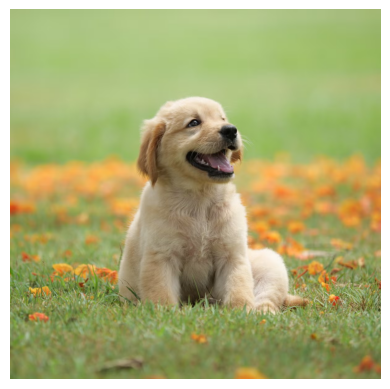

[program.cpp:154] InternalConsistency verification requested but not available
[ETCoreMLModelManager.mm:474] Cache Hit: Successfully retrieved compiled model with identifier=executorch_c8db98e3-54dc-4043-9fc8-c7ed7a9ef71a_all from the models cache.
[ETCoreMLModelManager.mm:474] Cache Hit: Successfully retrieved compiled model with identifier=executorch_d3df711d-f007-44a7-b11b-3a922679698b_all from the models cache.


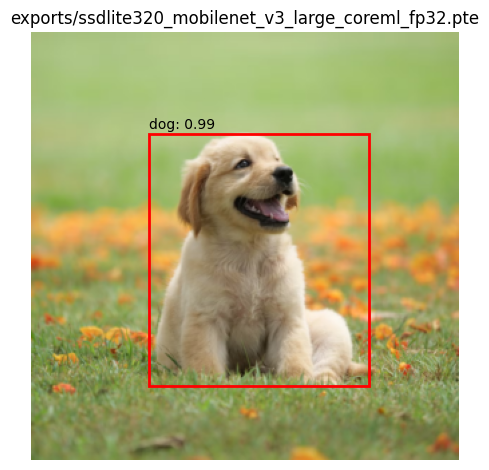

In [8]:
print("Visual inspection...")

img = decode_image("assets/dog.png")
plt.imshow(F.to_pil_image(img))
plt.axis("off")
plt.show()

for constructor in model_constructors:
    img = decode_image("assets/dog.png")
    img = preprocess(img)

    path = MODEL_PATH[constructor.__name__]
    runtime = Runtime.get()
    program = runtime.load_program(path)
    output = program.load_method("forward").execute([img])  # type: ignore

    visualize_predictions(img, {"boxes": output[0], "scores": output[1], "labels": output[2]}, title=path)